# ClaimGuard: Million-Claim Denial Risk & Review Prioritization
**Author: Rupak Kumar Dey | Independent portfolio project | Synthetic data**

Predict pre-submission claim denial risk, calibrate probabilities, and allocate a limited review budget using transparent financial assumptions. Builds **1,000,000 synthetic claim records**, a SQL analytics layer, temporal ML evaluation, capacity-based queues, subgroup analysis and drift checks.

This is an operational decision-support prototype, not a deployed payer system. No patient data, API key or external dataset download is required. Synthetic labels are generated by documented rules: performance measures recovery of those rules and does not establish real-world effectiveness.

**Run:** upload this `.ipynb` to Google Colab or Jupyter and select Run all. CPU only. The default run creates one million rows but caps model training at 120,000 rows. Allow several minutes and approximately 2–4 GB RAM; actual usage depends on environment. Change `N_CLAIMS` for smaller/larger experiments. GitHub displays saved notebook outputs; it does not execute notebooks.

**Skills demonstrated:** Python, pandas, NumPy, SQL window functions, scikit-learn, temporal validation, imbalanced classification, calibration, permutation importance, operational prioritization and monitoring.

In [1]:
import sys, subprocess, importlib.util
required = {'numpy':'numpy', 'pandas':'pandas', 'sklearn':'scikit-learn', 'matplotlib':'matplotlib', 'joblib':'joblib'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, sqlite3, json, platform, joblib
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
SEED = 42
N_CLAIMS = 1_000_000
MAX_TRAIN = 120_000
REVIEW_FRACTION = 0.05
REVIEW_COST = 12.0
PREVENTABLE_FRACTION = 0.35  # hypothetical assumption, NOT a measured effect
OUT = Path('claimguard_outputs'); OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
print({'python':platform.python_version(), 'sklearn':sklearn.__version__, 'rows':N_CLAIMS})

{'python': '3.12.14', 'sklearn': '1.8.0', 'rows': 1000000}


## 1. Data contract and synthetic generator
One row represents an initial claim at submission. All model inputs exist at submission; `denied` is a simulated later adjudication outcome. Toy payer and procedure group codes are not validated CPT/ICD coding. Claim amounts are billed charges, **not collectible cash**. `patient_id` is synthetic and is excluded from modeling.

The generator introduces a late-period payer shift, missing charges and duplicate ingested records. Identifiers and outcomes are excluded from features. No post-adjudication payment or denial reason enters training. There are no patient-specific latent effects; repeated patients do not create useful identity signals here. Real data needs patient/provider leakage checks and label-maturity cutoffs.

In [2]:
n = N_CLAIMS
day = rng.integers(0, 730, n)
payer = rng.integers(0, 5, n)
amount = np.round(rng.lognormal(6.0, 0.85, n).clip(25, 25000), 2)
auth_missing = rng.binomial(1, .12, n)
eligibility_issue = rng.binomial(1, .08, n)
coding_issue = rng.binomial(1, .10, n)
submission_delay = rng.integers(0, 100, n)
procedure_group = rng.integers(0, 8, n)
logit = (-3.4 + 1.4*auth_missing + 1.7*eligibility_issue + 1.15*coding_issue
         + .012*submission_delay + .22*(payer==2) + .30*(procedure_group==6)
         + .25*(auth_missing*(procedure_group==6)) + .18*np.log1p(amount/1000)
         + .45*((day>=620)&(payer==2)))
prob = 1/(1+np.exp(-logit))
claims = pd.DataFrame({'claim_id':np.arange(n), 'patient_id':rng.integers(0,max(1,n//4),n),
    'service_date':pd.Timestamp('2024-01-01')+pd.to_timedelta(day,unit='D'),
    'submission_delay':submission_delay, 'payer':payer, 'procedure_group':procedure_group,
    'billed_amount':amount, 'auth_missing':auth_missing, 'eligibility_issue':eligibility_issue,
    'coding_issue':coding_issue, 'denied':rng.binomial(1,prob)})
claims['submission_date'] = claims.service_date + pd.to_timedelta(claims.submission_delay,unit='D')
claims.loc[rng.choice(n, max(1,n//100), replace=False), 'billed_amount'] = np.nan
raw = pd.concat([claims, claims.sample(frac=.005,random_state=SEED)],ignore_index=True)
dupes = int(raw.claim_id.duplicated().sum())
claims = raw.drop_duplicates('claim_id').copy()
del raw, amount, logit, prob
assert len(claims)==n and claims.claim_id.is_unique
assert set(claims.denied.unique())=={0,1}
assert (claims.submission_date>=claims.service_date).all()
print({'clean_claims':len(claims),'duplicates_removed':dupes,
       'missing_amounts':int(claims.billed_amount.isna().sum()),'denial_rate':round(claims.denied.mean(),4)})
print(claims.head().to_string(index=False))

{'clean_claims': 1000000, 'duplicates_removed': 5000, 'missing_amounts': 10000, 'denial_rate': np.float64(0.1248)}
 claim_id  patient_id service_date  submission_delay  payer  procedure_group  billed_amount  auth_missing  eligibility_issue  coding_issue  denied submission_date
        0       61847   2024-03-06                78      4                2         727.96             0                  0             0       0      2024-05-23
        1      102396   2025-07-18                44      1                2         622.57             0                  0             0       1      2025-08-31
        2      247351   2025-04-22                86      3                6         503.11             0                  0             0       0      2025-07-17
        3       79136   2024-11-16                95      0                6         159.17             0                  0             1       0      2025-02-19
        4      204044   2024-11-12                 7      3           

## 2. SQL operational analytics
SQLite keeps the project self-contained. The window query ranks payer groups by billed charges associated with simulated denials. This is exposure, not realized loss. The table contains synthetic data only.

In [3]:
con = sqlite3.connect(OUT/'claims.sqlite')
claims.to_sql('claims',con,if_exists='replace',index=False,chunksize=25000)
con.execute('CREATE UNIQUE INDEX IF NOT EXISTS ix_claim_id ON claims(claim_id)')
sql = """WITH payer_summary AS (
 SELECT payer, COUNT(*) AS claims, AVG(denied) AS denial_rate,
 SUM(CASE WHEN denied=1 THEN COALESCE(billed_amount,0) ELSE 0 END) AS denied_billed_exposure
 FROM claims GROUP BY payer)
 SELECT *, DENSE_RANK() OVER (ORDER BY denied_billed_exposure DESC) AS exposure_rank
 FROM payer_summary ORDER BY exposure_rank"""
print(pd.read_sql_query(sql,con).round(3).to_string(index=False))
(OUT/'payer_analytics.sql').write_text(sql)
con.close()

Empty DataFrame
Columns: [payer, claims, denial_rate, denied_billed_exposure, exposure_rank]
Index: []


## 3. Temporal split and leakage controls
Partition by submission date: training before May 2025, calibration in May–July, validation in August–September and untouched test from October. Train models only on the training window; fit probability calibration only on calibration data; select model only on validation. The test simulates a later policy shift. Real claims can take months to mature: exclude unresolved labels before implementing this design with production data.

In [4]:
FEATURES = ['submission_delay','payer','procedure_group','billed_amount','auth_missing','eligibility_issue','coding_issue']
# Use one-hot payer and procedure indicators; fixed public vocabularies, not learned from test.
def features(frame):
    x = frame[['submission_delay','billed_amount','auth_missing','eligibility_issue','coding_issue']].copy()
    for col, levels in [('payer',range(5)),('procedure_group',range(8))]:
        for level in levels: x[f'{col}_{level}'] = (frame[col]==level).astype('int8')
    return x
train = claims[claims.submission_date < '2025-05-01'].sample(frac=1,random_state=SEED).head(MAX_TRAIN)
cal = claims[(claims.submission_date >= '2025-05-01') & (claims.submission_date < '2025-08-01')]
val = claims[(claims.submission_date >= '2025-08-01') & (claims.submission_date < '2025-10-01')]
test = claims[claims.submission_date >= '2025-10-01'].copy()
assert train.submission_date.max() < cal.submission_date.min()
assert cal.submission_date.max() < val.submission_date.min()
assert val.submission_date.max() < test.submission_date.min()
Xtr, Xcal, Xval, Xtest = map(features,[train,cal,val,test])
for name, df in [('train',train),('calibration',cal),('validation',val),('test',test)]:
    assert df.denied.nunique()==2
    print(name,len(df),str(df.submission_date.min().date()),str(df.submission_date.max().date()))
models = {
 'dummy':make_pipeline(SimpleImputer(),DummyClassifier(strategy='prior')),
 'logistic':make_pipeline(SimpleImputer(),StandardScaler(),LogisticRegression(max_iter=300,random_state=SEED)),
 'boosting':make_pipeline(SimpleImputer(),HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,l2_regularization=10,random_state=SEED))}
def logodds(p):
    p = np.clip(p,1e-6,1-1e-6)
    return np.log(p/(1-p)).reshape(-1,1)
calibrators = {}; validation = []
for name, model in models.items():
    model.fit(Xtr,train.denied)
    pcal = model.predict_proba(Xcal)[:,1]
    calibrator = LogisticRegression(C=1e6).fit(logodds(pcal),cal.denied)
    calibrators[name] = calibrator
    pv = calibrator.predict_proba(logodds(model.predict_proba(Xval)[:,1]))[:,1]
    validation.append({'model':name,'AP':average_precision_score(val.denied,pv),'Brier':brier_score_loss(val.denied,pv)})
validation = pd.DataFrame(validation).sort_values(['AP','Brier'],ascending=[False,True])
best = validation.iloc[0]['model']
model, calibrator = models[best], calibrators[best]
print(validation.to_string(index=False)); print('Selected using validation AP:',best)
def predict_risk(frame):
    return calibrator.predict_proba(logodds(model.predict_proba(features(frame))[:,1]))[:,1]
test['risk'] = predict_risk(test)
metrics = {'model':best,'test_rows':len(test),'test_prevalence':float(test.denied.mean()),
 'roc_auc':float(roc_auc_score(test.denied,test.risk)),
 'average_precision':float(average_precision_score(test.denied,test.risk)),
 'brier':float(brier_score_loss(test.denied,test.risk)),
 'log_loss':float(log_loss(test.denied,test.risk))}
print(json.dumps(metrics,indent=2))

train 120000 2024-01-01 2025-04-30
calibration 126033 2025-05-01 2025-07-31
validation 83189 2025-08-01 2025-09-30
test 192116 2025-10-01 2026-04-08
   model       AP    Brier
logistic 0.347511 0.094626
boosting 0.344344 0.094886
   dummy 0.122420 0.107434
Selected using validation AP: logistic
{
  "model": "logistic",
  "test_rows": 192116,
  "test_prevalence": 0.13889525078598347,
  "roc_auc": 0.7319575485349872,
  "average_precision": 0.3607818497457028,
  "brier": 0.10561882808933666,
  "log_loss": 0.3555336777808585
}


## 4. Capacity-aware review queue and scenario economics
Review 5% of test claims. Compare seeded random review, highest risk, highest billed value and a financial scenario score. The score is `risk × billed charge × preventable fraction − review cost`; this uses billed amounts as a proxy. **It is not expected collectible revenue or proven savings.** Missing charges receive the training median. No test labels are used to construct queues. Outcomes are used only afterward to evaluate the queues.

Capacity is an input assumption, not tuned on test results. A real workflow should use expected allowed amounts, denial-specific preventability estimates, review time, appeal costs and a prospective controlled evaluation.

In [5]:
k = max(1,int(len(test)*REVIEW_FRACTION))
test['scenario_value'] = test.risk * test.billed_amount.fillna(train.billed_amount.median()) * PREVENTABLE_FRACTION - REVIEW_COST
queues = {'random':test.sample(n=k,random_state=SEED),
          'risk':test.nlargest(k,'risk'), 'amount':test.nlargest(k,'billed_amount'),
          'scenario_value':test.nlargest(k,'scenario_value')}
rows=[]
for name,q in queues.items():
    rows.append({'strategy':name,'reviewed':len(q),'precision':float(q.denied.mean()),
     'denial_recall':float(q.denied.sum()/test.denied.sum()),
     'denied_billed_exposure':float(q.loc[q.denied==1,'billed_amount'].sum()),
     'scenario_net_proxy':float(q.loc[q.denied==1,'billed_amount'].sum()*PREVENTABLE_FRACTION-len(q)*REVIEW_COST)})
queue_results = pd.DataFrame(rows)
print(queue_results.round(3).to_string(index=False))
print('Sensitivity: hypothetical proxy net, NOT savings')
exposure = queue_results.set_index('strategy').loc['scenario_value','denied_billed_exposure']
for preventable in [.1,.2,.35,.5]:
    print(preventable, round(exposure*preventable-k*REVIEW_COST,2))
queue_results.to_csv(OUT/'queue_comparison.csv',index=False)
queues['scenario_value'].sort_values('scenario_value',ascending=False).to_csv(OUT/'review_queue.csv',index=False)

      strategy  reviewed  precision  denial_recall  denied_billed_exposure  scenario_net_proxy
        random      9605      0.145          0.052               832254.17          176028.959
          risk      9605      0.515          0.185              3179124.51          997433.578
        amount      9605      0.148          0.053              3563053.07         1131808.574
scenario_value      9605      0.363          0.131              5073542.73         1660479.956
Sensitivity: hypothetical proxy net, NOT savings
0.1 392094.27
0.2 899448.55
0.35 1660479.96
0.5 2421511.37


## 5. Calibration, subgroup audit, feature importance and drift
Subgroups by payer assess operational performance differences; they do not establish demographic fairness. Permutation importance reports predictive association, not causal drivers. PSI uses training quantile bins for numeric features and fixed levels for categorical features; >0.2 is an illustrative review flag, not a universal rule.

In [6]:
subgroups=[]
for payer,g in test.groupby('payer'):
    subgroups.append({'payer':int(payer),'n':len(g),'prevalence':g.denied.mean(),
       'AP':average_precision_score(g.denied,g.risk),'Brier':brier_score_loss(g.denied,g.risk)})
print(pd.DataFrame(subgroups).round(4).to_string(index=False))
sub = test.sample(n=min(3000,len(test)),random_state=SEED)
imp = permutation_importance(model,features(sub),sub.denied,n_repeats=3,scoring='average_precision',random_state=SEED)
importance = pd.Series(imp.importances_mean,index=Xtr.columns).sort_values(ascending=False)
print('Top feature associations (uncalibrated base model):'); print(importance.head(8))
def psi(a,b,categorical=False):
    if categorical:
        levels = sorted(set(a.dropna())|set(b.dropna()))
        p = a.value_counts(normalize=True).reindex(levels,fill_value=0).values
        q = b.value_counts(normalize=True).reindex(levels,fill_value=0).values
    else:
        edges = np.unique(np.quantile(a.dropna(),np.linspace(0,1,11)))
        if len(edges)<2: return float('nan')
        edges[0], edges[-1] = -np.inf,np.inf
        p = np.histogram(a.dropna(),edges)[0]; q = np.histogram(b.dropna(),edges)[0]
        p = p/p.sum(); q = q/q.sum()
    p,q = np.clip(p,1e-6,None),np.clip(q,1e-6,None)
    return float(np.sum((q-p)*np.log(q/p)))
drift = pd.DataFrame([{'feature':c,'PSI':psi(train[c],test[c],c in ['payer','procedure_group','auth_missing','eligibility_issue','coding_issue']),
 'train_missing':train[c].isna().mean(),'test_missing':test[c].isna().mean()} for c in FEATURES])
print(drift.round(4).to_string(index=False))
fig, axes = plt.subplots(1,3,figsize=(15,4))
fraction, mean = calibration_curve(test.denied,test.risk,n_bins=10,strategy='quantile')
axes[0].plot(mean,fraction,'o-'); axes[0].plot([0,1],[0,1],'--'); axes[0].set(title='Test calibration',xlabel='Predicted risk',ylabel='Observed denial rate')
queue_results.plot.bar(x='strategy',y='precision',ax=axes[1],legend=False,title='Precision at 5% review capacity')
importance.head(8).sort_values().plot.barh(ax=axes[2],title='Permutation importance (AP)')
fig.tight_layout(); fig.savefig(OUT/'evaluation.png',dpi=140); plt.show()
drift.to_csv(OUT/'drift_report.csv',index=False)

 payer     n  prevalence     AP  Brier
     0 38420      0.1261 0.3363 0.0981
     1 38394      0.1249 0.3357 0.0973
     2 38481      0.1902 0.4277 0.1364
     3 38325      0.1274 0.3311 0.0994
     4 38496      0.1258 0.3480 0.0969
Top feature associations (uncalibrated base model):
auth_missing         0.101294
eligibility_issue    0.085102
coding_issue         0.054247
submission_delay     0.022806
payer_2              0.004181
procedure_group_6    0.003821
payer_4              0.000675
payer_1              0.000344
dtype: float64
          feature    PSI  train_missing  test_missing
 submission_delay 0.0788         0.0000        0.0000
            payer 0.0000         0.0000        0.0000
  procedure_group 0.0001         0.0000        0.0000
    billed_amount 0.0000         0.0102        0.0099
     auth_missing 0.0000         0.0000        0.0000
eligibility_issue 0.0000         0.0000        0.0000
     coding_issue 0.0000         0.0000        0.0000


## 6. Reusable scoring artifact, reproducibility and GitHub materials
Artifacts are exported locally after a run. The scoring bundle contains trusted Python objects; never load untrusted joblib files. A production API, clinical validation, external data benchmark, cloud deployment and actual savings study are outside this prototype.

The single notebook is sufficient for GitHub upload. For a more browsable repository, also upload the generated README, requirements and model card. Avoid committing the SQLite database, all claim records or model binary. The dataset regenerates deterministically from the seed. These exported artifacts demonstrate batch scoring, not a deployed service.

# ClaimGuard: Million-Claim Denial Risk & Review Prioritization
Independent synthetic healthcare ML portfolio by Rupak Kumar Dey.

## Business question
Which claims should a limited operations team review before submission?

## Dataset
1,000,000 reproducible synthetic initial claims, five toy payers and eight procedure groups.
No real patient records. Synthetic outcomes are generated by documented probabilistic rules.

## Workflow
Data-quality checks → SQL payer analytics → temporal train/calibration/validation/test →
baselines and boosted trees → probability calibration → review queue → monitoring.
Training uses at most 120,000 rows for CPU practicality; the full dataset supports analytics.

## Reproduced outcomes (synthetic held-out data)
- Selected model: logistic
- Test claims: 192,116
- ROC-AUC: 0.7320
- Average precision: 0.3608; prevalence baseline: 0.1389
- Brier score: 0.1056
- Review capacity: 5%; queue comparisons in queue_comparison.csv.
These are simulation results, not cl

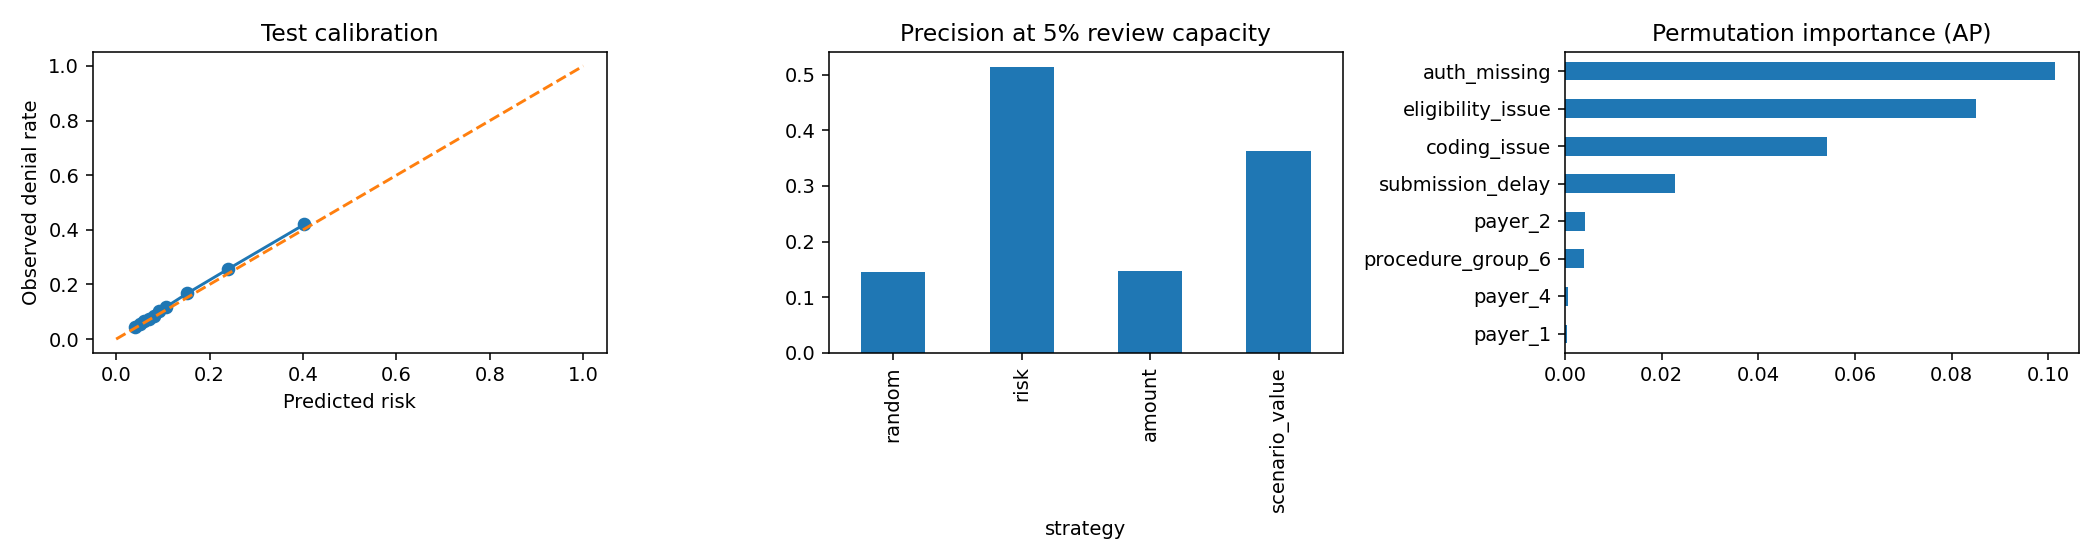

In [7]:
bundle = {'model':model,'calibrator':calibrator,'feature_columns':list(Xtr.columns),'seed':SEED}
joblib.dump(bundle,OUT/'scoring_bundle.joblib')
loaded = joblib.load(OUT/'scoring_bundle.joblib')
smoke = test.head(20)
restored = loaded['calibrator'].predict_proba(logodds(loaded['model'].predict_proba(features(smoke))[:,1]))[:,1]
assert np.allclose(restored,predict_risk(smoke))
assert np.isfinite(test.risk).all() and test.risk.between(0,1).all()
assert len(queues['scenario_value'])==k
metrics['generated_claims']=n
metrics['training_rows']=len(train)
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))
requirements = '\n'.join([f'numpy=={np.__version__}',f'pandas=={pd.__version__}',f'scikit-learn=={sklearn.__version__}',f'joblib=={joblib.__version__}','matplotlib'])+'\n'
(OUT/'requirements.txt').write_text(requirements)
readme = f"""# ClaimGuard: Million-Claim Denial Risk & Review Prioritization
Independent synthetic healthcare ML portfolio by Rupak Kumar Dey.

## Business question
Which claims should a limited operations team review before submission?

## Dataset
{n:,} reproducible synthetic initial claims, five toy payers and eight procedure groups.
No real patient records. Synthetic outcomes are generated by documented probabilistic rules.

## Workflow
Data-quality checks → SQL payer analytics → temporal train/calibration/validation/test →
baselines and boosted trees → probability calibration → review queue → monitoring.
Training uses at most {MAX_TRAIN:,} rows for CPU practicality; the full dataset supports analytics.

## Reproduced outcomes (synthetic held-out data)
- Selected model: {best}
- Test claims: {len(test):,}
- ROC-AUC: {metrics['roc_auc']:.4f}
- Average precision: {metrics['average_precision']:.4f}; prevalence baseline: {metrics['test_prevalence']:.4f}
- Brier score: {metrics['brier']:.4f}
- Review capacity: {REVIEW_FRACTION:.0%}; queue comparisons in queue_comparison.csv.
These are simulation results, not clinical evidence or production savings.

## Run
Open ClaimGuard_Healthcare_Million_Claims.ipynb in Colab/Jupyter and Run all.
Missing dependencies install automatically. No credentials required.
Outputs are written to claimguard_outputs/. Do not commit the database or model binary.

## Limitations
Synthetic label-rule recovery; no external validation. No causal intervention estimate.
Charges are not allowed payments. Label maturity and prospective monitoring are required for real deployment.
No protected demographic audit; payer subgroups alone do not establish fairness.

## Suggested resume bullet
Built an independent healthcare claims ML prototype using {n:,} synthetic records, SQL analytics,
temporal evaluation, probability calibration and capacity-based review prioritization;
achieved {metrics['average_precision']:.3f} average precision on a synthetic temporal test set.

## Repository description
Healthcare claims ML portfolio: 1M synthetic claims, SQL analytics, calibrated denial-risk models,
leakage-aware temporal evaluation, review prioritization and drift monitoring.
"""
(OUT/'README.md').write_text(readme)
(OUT/'MODEL_CARD.md').write_text('Independent synthetic portfolio. Intended use: educational batch review prioritization. Not for claim adjudication or clinical decisions. No real-world validation.\n'+json.dumps(metrics,indent=2))
(OUT/'.gitignore').write_text('*.sqlite\n*.joblib\nreview_queue.csv\n__pycache__/\n.ipynb_checkpoints/\n')
print(readme)
print('All integrity and scoring round-trip checks passed.')

## Interview talking points and next steps
- Explain why average precision and calibrated probabilities matter for low-prevalence denials.
- Explain why a temporal split and separate calibration window are preferable to random splitting here.
- Discuss the difference between risk ranking and charge-weighted prioritization.
- State that apparent financial benefit is a sensitivity scenario; causal savings require prospective evidence.
- For a stronger next version, obtain authorized real claims, define mature denial labels and run external validation. Public synthetic EHR claims may lack suitable denial labels; do not invent them.

**Job-market motivation (checked 3 November 2026):** employer postings emphasize claims experience, Python/SQL, validation, calibration, explainability and monitoring. This project demonstrates those skills, without claiming to meet every senior-role requirement.
- [UnitedHealth Group: AI/ML Engineer](https://careers.unitedhealthgroup.com/en/job/hyderabad/ai-ml-engineer/34088/102629080048)
- [Amgen: Machine Learning Engineer, AI Studio](https://amgen.wd1.myworkdayjobs.com/en-US/Careers/job/Machine-Learning-Engineer--AI-Studio_R-251201)

**Suggested repository name:** `claimguard-healthcare-denial-risk`

**GitHub upload:** Create a public repository with that name → Add file → Upload files → choose this notebook → Commit changes. Optionally add the generated README and requirements after running. Do not describe this as client work or deployment.